<a href="https://colab.research.google.com/github/mahapatramadhu-ops/python-/blob/main/traffic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv("/content/traffic.csv")

print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

              DateTime  Junction  Vehicles           ID
0  2015-11-01 00:00:00         1        15  20151101001
1  2015-11-01 01:00:00         1        13  20151101011
2  2015-11-01 02:00:00         1        10  20151101021
3  2015-11-01 03:00:00         1         7  20151101031
4  2015-11-01 04:00:00         1         9  20151101041

Dataset Shape:
(48120, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DateTime  48120 non-null  object
 1   Junction  48120 non-null  int64 
 2   Vehicles  48120 non-null  int64 
 3   ID        48120 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None

Missing Values:
DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64

Statistical Summary:
           Junction      Vehicles            ID
count  48120.000000  48120.000000  4.812000e+04
mean       2.180549 

In [3]:
df['DateTime'] = pd.to_datetime(df['DateTime'])

df = df.dropna()

df['Hour'] = df['DateTime'].dt.hour
df['Day'] = df['DateTime'].dt.day
df['Month'] = df['DateTime'].dt.month
df['Year'] = df['DateTime'].dt.year
df['DayOfWeek'] = df['DateTime'].dt.dayofweek

print(df.head())

             DateTime  Junction  Vehicles           ID  Hour  Day  Month  \
0 2015-11-01 00:00:00         1        15  20151101001     0    1     11   
1 2015-11-01 01:00:00         1        13  20151101011     1    1     11   
2 2015-11-01 02:00:00         1        10  20151101021     2    1     11   
3 2015-11-01 03:00:00         1         7  20151101031     3    1     11   
4 2015-11-01 04:00:00         1         9  20151101041     4    1     11   

   Year  DayOfWeek  
0  2015          6  
1  2015          6  
2  2015          6  
3  2015          6  
4  2015          6  


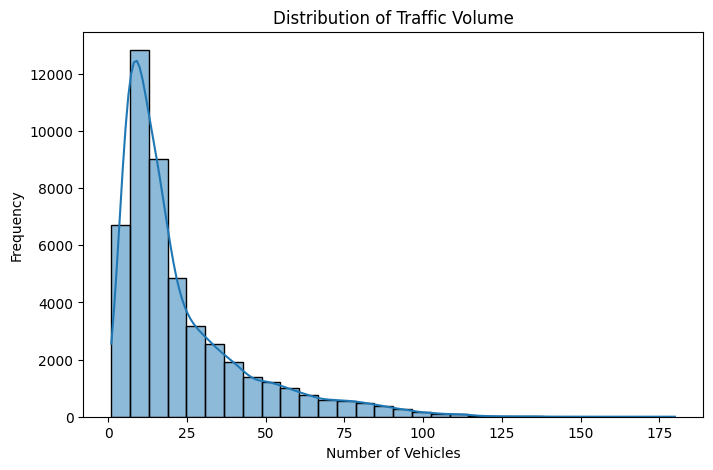

In [4]:
plt.figure(figsize=(8,5))

sns.histplot(df['Vehicles'], bins=30, kde=True)

plt.title("Distribution of Traffic Volume")
plt.xlabel("Number of Vehicles")
plt.ylabel("Frequency")

plt.show()

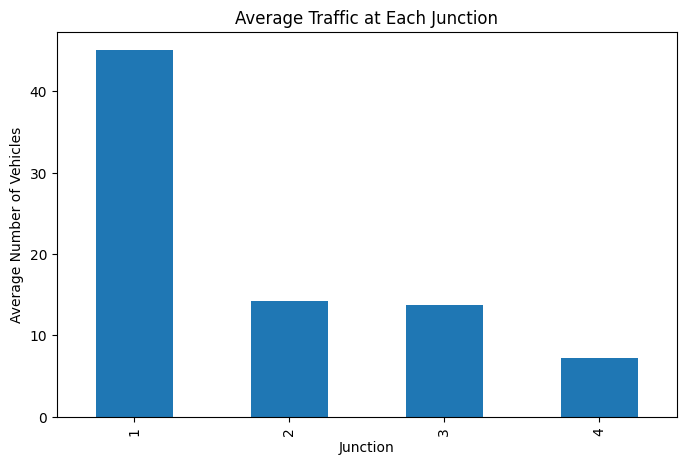

In [5]:
junction = df.groupby('Junction')['Vehicles'].mean()

junction.plot(kind='bar', figsize=(8,5))

plt.title("Average Traffic at Each Junction")
plt.xlabel("Junction")
plt.ylabel("Average Number of Vehicles")

plt.show()

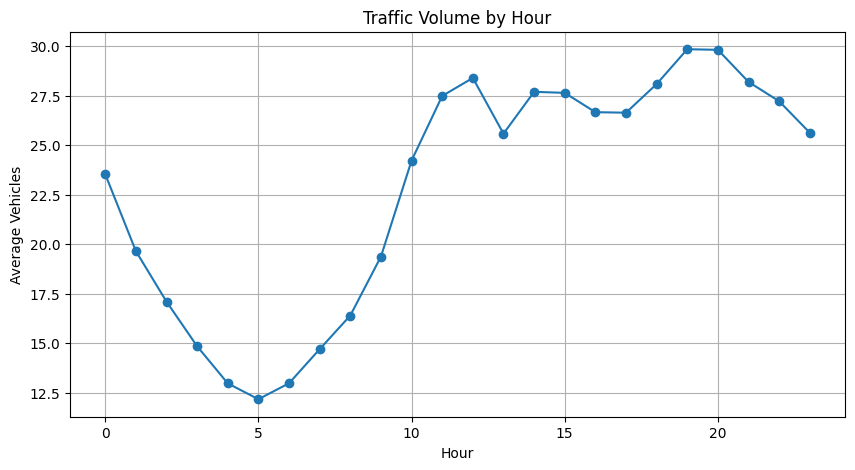

In [6]:
hourly = df.groupby('Hour')['Vehicles'].mean()

plt.figure(figsize=(10,5))

plt.plot(hourly.index, hourly.values, marker='o')

plt.title("Traffic Volume by Hour")
plt.xlabel("Hour")
plt.ylabel("Average Vehicles")

plt.grid()
plt.show()

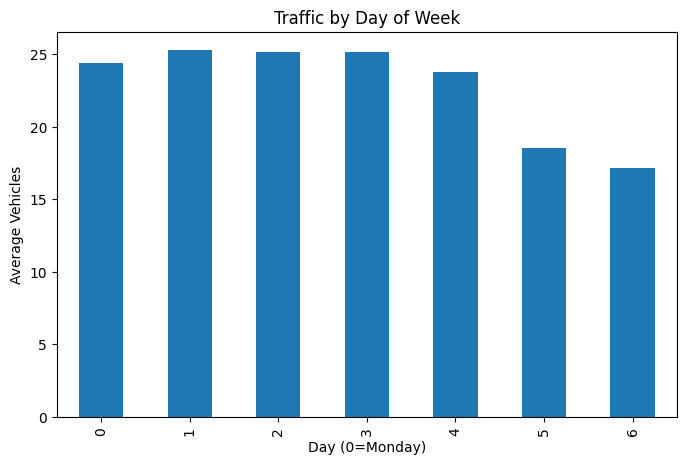

In [7]:
daily = df.groupby('DayOfWeek')['Vehicles'].mean()

daily.plot(kind='bar', figsize=(8,5))

plt.title("Traffic by Day of Week")
plt.xlabel("Day (0=Monday)")
plt.ylabel("Average Vehicles")

plt.show()

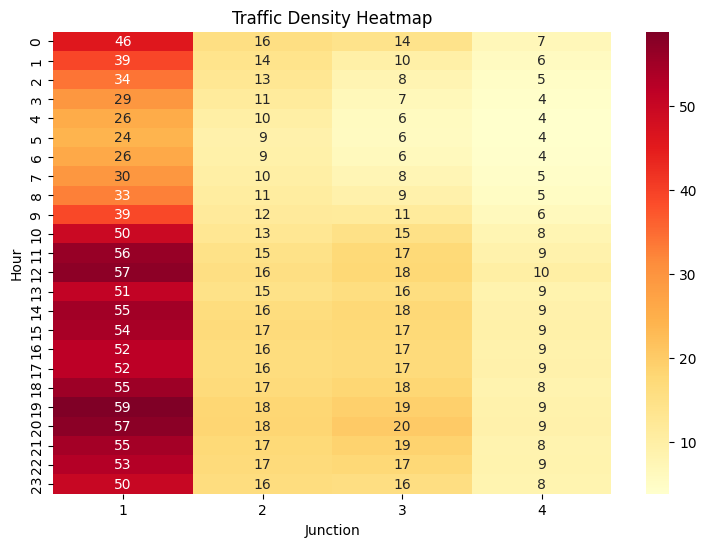

In [8]:
heatmap_data = df.pivot_table(
    values='Vehicles',
    index='Hour',
    columns='Junction',
    aggfunc='mean'
)

plt.figure(figsize=(9,6))

sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlOrRd')

plt.title("Traffic Density Heatmap")

plt.show()

In [9]:
df = df.sort_values('DateTime')

X = df[['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek']]

y = df['Vehicles']

# Split data chronologically
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Create model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("Model Training Completed!")

Model Training Completed!


In [10]:
print("Mean Absolute Error:",
      mean_absolute_error(y_test, y_pred))

print("Mean Squared Error:",
      mean_squared_error(y_test, y_pred))

print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2 Score:",
      r2_score(y_test, y_pred))

Mean Absolute Error: 13.97939110556941
Mean Squared Error: 414.6267918744805
Root Mean Squared Error: 20.36238669396298
R2 Score: 0.44059104971099916


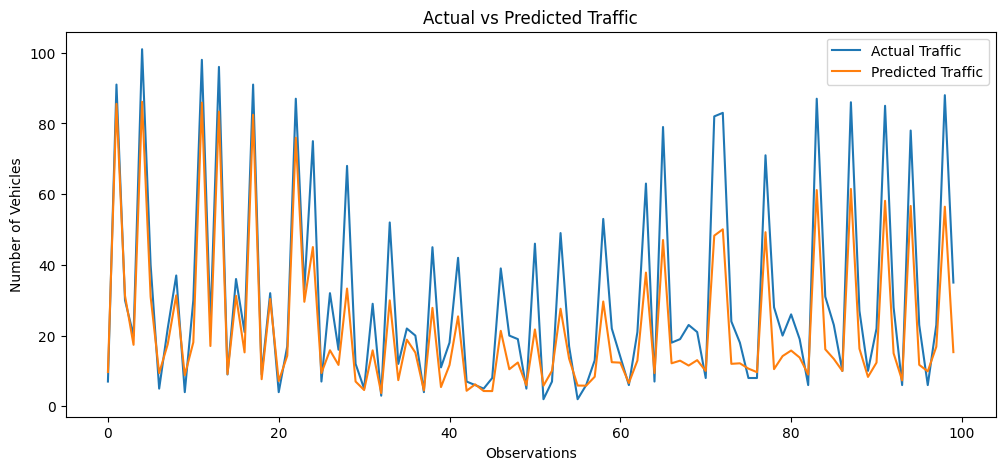

In [11]:
plt.figure(figsize=(12,5))

plt.plot(y_test.values[:100],
         label="Actual Traffic")

plt.plot(y_pred[:100],
         label="Predicted Traffic")

plt.title("Actual vs Predicted Traffic")

plt.xlabel("Observations")
plt.ylabel("Number of Vehicles")

plt.legend()
plt.show()

In [12]:
print("SMART TRAFFIC MANAGEMENT ANALYSIS")

print("Total Records:", len(df))

print("Number of Junctions:",
      df['Junction'].nunique())

print("Average Vehicles:",
      df['Vehicles'].mean())

print("Maximum Vehicles:",
      df['Vehicles'].max())

print("Minimum Vehicles:",
      df['Vehicles'].min())

print("Highest Traffic Hour:",
      hourly.idxmax())

SMART TRAFFIC MANAGEMENT ANALYSIS
Total Records: 48120
Number of Junctions: 4
Average Vehicles: 22.79133416458853
Maximum Vehicles: 180
Minimum Vehicles: 1
Highest Traffic Hour: 19
